# Pipeline A vs Pipeline B: Unified Evaluation and Detector Swap

**Course:** CS 5567 – Deep Learning  **Runtime:** GPU

**Objective.** This notebook compares the two pipelines of our team with the **same evaluation code** on the same held-out sequence (MOT16-09).

- **Pipeline A**: Faster R-CNN, Siamese ResNet-18 with triplet loss, and a custom tracker (Kalman filter, Hungarian matching, offline rules). Code: the public repository of Pipeline A (the link is in code cell 2).
- **Pipeline B**: YOLO, ResNet-50 ReID with triplet loss, BoT-SORT, and appearance-based split/merge repair (Notebooks 03–05).

Both pipelines use the same data split (train on MOT16-02, 04, 05, 10, 11, 13; validate on MOT16-09). Each pipeline reported its own metrics with its own code, so the published numbers are not directly comparable.

**Procedure**
1. Score the saved tracks of both pipelines with TrackEval (HOTA, MOTA, IDF1, ID switches, false positives, false negatives). *No weights of Pipeline A are needed.*
2. Compare the two detectors with one evaluator: average precision, precision-recall curves, and recall by visibility. *Needs the detector weights of Pipeline A or its cached detections.* Part 2b compares the saved tracks and needs no weights. Part 2b compares the saved tracks and needs no weights.
3. Swap the detector inside the tracker of Pipeline A: feed it the YOLO detections and compare with its own Faster R-CNN detections. *Needs the ReID weights of Pipeline A.*
4. Compare the ReID models on one query/gallery protocol. *Needs the ReID weights of Pipeline A and of Pipeline B (Notebook 05).*

Parts 2–4 are skipped automatically when the required files are not found.

**Key result.** One table with HOTA, IDF1, MOTA, and ID switches for all configurations, computed by the same code.

In [1]:
# 1. Setup: Drive, packages, Pipeline B paths
from google.colab import drive
drive.mount('/content/drive')
!pip -q install ultralytics scikit-learn tqdm
from pathlib import Path
import sys, time, json, shutil, subprocess, pickle, configparser, random
import numpy as np, pandas as pd, cv2, torch, torch.nn as nn, torch.nn.functional as F, torchvision
import torchvision.transforms as T
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

CANDIDATES = [Path('/content/drive/MyDrive/MOT16_project/Backup'),
              Path('/content/drive/MyDrive/MOT16_project'),
              Path('/content/drive/MyDrive/DL_Video_Tracking ')]      # trailing space is intentional
BASE = next((p for p in CANDIDATES if (p/'yolo_mot16_best.pt').exists()), None)
assert BASE, 'yolo_mot16_best.pt not found - run Notebook 03 first'
RESULTS = BASE/'results'; RESULTS.mkdir(exist_ok=True)
MOT_DRIVE = next((p for p in [BASE/'MOT16', BASE.parent/'MOT16', BASE.parent/'Backup'/'MOT16'] if (p/'train').exists()), None)
assert MOT_DRIVE, 'MOT16 folder not found'
dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
GPU = torch.cuda.get_device_name(0) if dev.type == 'cuda' else 'CPU'
print('BASE:', BASE, '| device:', GPU)

Mounted at /content/drive
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 80.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 11.4 MB/s eta 0:00:00
BASE: /content/drive/MyDrive/MOT16_project/Backup | device: NVIDIA A100-SXM4-40GB


In [2]:
# 2. Get the code of Pipeline A (public repository) and look for its weights
!rm -rf /content/pipelineA && git clone -q https://github.com/Rehan-rahim/mot16-pedestrian-tracking_project /content/pipelineA
sys.path.insert(0, '/content/pipelineA/src')
import config as A_cfg, mot_data as A_data, tracker as A_tracker, detector as A_det, reid as A_reid     # Pipeline A modules

# Where are the weights of Pipeline A? Its Drive folder is called 'DL_Project_MOT'. Ask the owner of Pipeline A to share it,
# or copy the two .pth files and the .pkl file into BASE/pipelineA.
A_ROOTS = [Path('/content/drive/MyDrive/DL_Project_MOT'), BASE/'pipelineA', BASE/'pipelineA_weights', BASE]
def find_file(name):
    for root in A_ROOTS:
        for sub in ('', 'weights'):
            p = root/sub/name
            if p.exists(): return p
    return None
A_DET_CKPT  = find_file('detector_frcnn_mot16.pth')
A_REID_CKPT = find_file('reid_resnet18_triplet.pth')
_cache_cands = [A_ROOTS[0]/'outputs'/'detections'/'MOT16-09_finetuned.pkl', BASE/'pipelineA'/'MOT16-09_finetuned.pkl']
A_DETS_CACHE = next((p for p in _cache_cands if p.exists()), None)
print('A detector weights :', A_DET_CKPT or 'NOT FOUND (parts 2-3 use cached detections if available)')
print('A ReID weights     :', A_REID_CKPT or 'NOT FOUND (parts 3-4 will be skipped)')
print('A cached detections:', A_DETS_CACHE or 'not found')

A detector weights : /content/drive/MyDrive/MOT16_project/Backup/pipelineA/detector_frcnn_mot16.pth
A ReID weights     : /content/drive/MyDrive/MOT16_project/Backup/pipelineA/reid_resnet18_triplet.pth
A cached detections: /content/drive/MyDrive/MOT16_project/Backup/pipelineA/MOT16-09_finetuned.pkl


In [3]:
# 3. Configuration and the validation sequence (local copy, with a check for unreadable frames)
SEQ = 'MOT16-09'
IMGSZ = 960
SEQ_DIR = Path('/content/MOT16')/'train'/SEQ
if not SEQ_DIR.exists():
    SEQ_DIR.parent.mkdir(parents=True, exist_ok=True); shutil.copytree(MOT_DRIVE/'train'/SEQ, SEQ_DIR)
IMG_DIR = SEQ_DIR/'img1'
cp = configparser.ConfigParser(); cp.read(SEQ_DIR/'seqinfo.ini')
N_FRAMES, W_IMG, H_IMG = int(cp['Sequence']['seqLength']), int(cp['Sequence']['imWidth']), int(cp['Sequence']['imHeight'])
bad = [f for f in range(1, N_FRAMES + 1) if cv2.imread(str(IMG_DIR/f'{f:06d}.jpg')) is None]
for f in bad: shutil.copy2(MOT_DRIVE/'train'/SEQ/'img1'/f'{f:06d}.jpg', IMG_DIR/f'{f:06d}.jpg')
print(SEQ, N_FRAMES, 'frames | unreadable before re-copy:', len(bad), '| after:', sum(cv2.imread(str(IMG_DIR/f'{f:06d}.jpg')) is None for f in bad))

MOT16-09 525 frames | unreadable before re-copy: 0 | after: 0


In [4]:
# 4. TrackEval (same setup as Notebooks 04 and 05)
!rm -rf /content/TrackEval && git clone -q https://github.com/JonathonLuiten/TrackEval /content/TrackEval
!find /content/TrackEval -name "*.py" -exec sed -i -E 's/np\.(float|int|bool)\b/\1/g' {} +
TE_ROOT = Path('/content/trackeval_data'); TE_GT, TE_TRACKERS = TE_ROOT/'gt', TE_ROOT/'trackers'
shutil.rmtree(TE_ROOT, ignore_errors=True); (TE_GT/SEQ/'gt').mkdir(parents=True); TE_TRACKERS.mkdir(parents=True)
shutil.copy(SEQ_DIR/'gt'/'gt.txt', TE_GT/SEQ/'gt'/'gt.txt'); shutil.copy(SEQ_DIR/'seqinfo.ini', TE_GT/SEQ/'seqinfo.ini')

def run_trackeval():
    names = sorted(p.name for p in TE_TRACKERS.iterdir() if p.is_dir())
    cmd = [sys.executable, 'scripts/run_mot_challenge.py', '--BENCHMARK', 'MOT16', '--SPLIT_TO_EVAL', 'train', '--SKIP_SPLIT_FOL', 'True',
           '--GT_FOLDER', str(TE_GT), '--TRACKERS_FOLDER', str(TE_TRACKERS), '--SEQ_INFO', SEQ,
           '--TRACKERS_TO_EVAL', *names, '--METRICS', 'HOTA', 'CLEAR', 'Identity', '--USE_PARALLEL', 'False',
           '--PRINT_CONFIG', 'False', '--PRINT_RESULTS', 'False', '--OUTPUT_SUMMARY', 'True', '--OUTPUT_DETAILED', 'False', '--PLOT_CURVES', 'False']
    res = subprocess.run(cmd, cwd='/content/TrackEval', capture_output=True, text=True)
    if res.returncode != 0:
        print(res.stdout[-3000:]); print(res.stderr[-3000:]); raise RuntimeError('TrackEval failed')
    return names

COLS = ['HOTA', 'DetA', 'AssA', 'MOTA', 'IDF1', 'IDSW', 'Frag', 'CLR_FP', 'CLR_FN']
def collect_results(names):
    rows = []
    for n in names:
        s = pd.read_csv(TE_TRACKERS/n/'pedestrian_summary.txt', sep=r'\s+')
        t = pd.read_csv(TE_TRACKERS/n/'data'/f'{SEQ}.txt', header=None)
        rows.append({'run': n, **{c: float(s.iloc[0][c]) for c in COLS if c in s.columns}, 'pred_ids': t[1].nunique()})
    return pd.DataFrame(rows).set_index('run')

def put_tracks(name, src):
    d = TE_TRACKERS/name/'data'; d.mkdir(parents=True, exist_ok=True); shutil.copy(src, d/f'{SEQ}.txt')

## Part 1: The saved tracks of both pipelines, scored by the same code

The tracks of Pipeline A are the file `results/tracks/MOT16-09.txt` in its repository. The tracks of Pipeline B come from Notebooks 04 and 05 (saved on Drive). All files are in MOT Challenge format.

,HOTA,DetA,AssA,MOTA,IDF1,IDSW,Frag,CLR_FP,CLR_FN,pred_ids
run,,,,,,,,,,
A_published,50.40,53.97,47.11,55.83,60.35,35.0,51.0,1073.0,1214.0,54
B_E0_pretrained_bytetrack,48.11,54.50,42.71,59.29,57.37,46.0,69.0,735.0,1359.0,92
B_E1_finetuned_bytetrack,47.94,58.99,39.12,64.77,55.77,42.0,91.0,532.0,1278.0,73
B_E2_finetuned_botsort,48.40,60.36,38.95,68.54,55.65,46.0,95.0,462.0,1146.0,72
B_repaired,55.30,60.25,50.89,68.35,68.04,56.0,96.0,462.0,1146.0,72


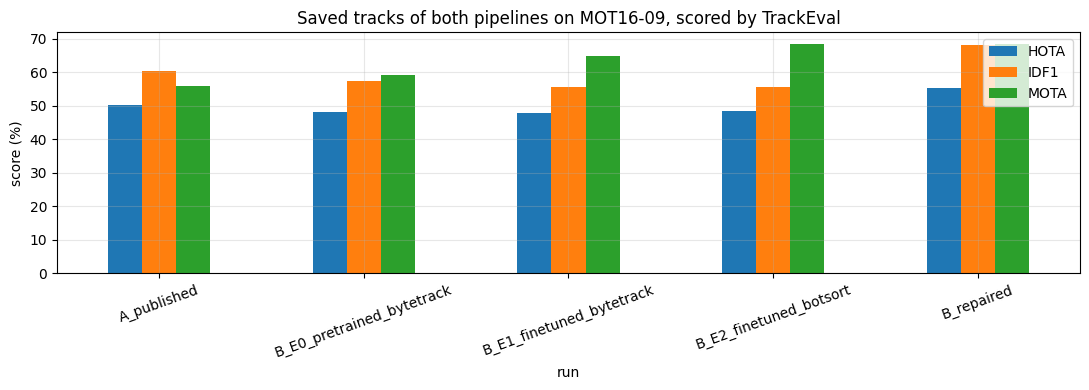

In [5]:
# 5. Load all saved tracks and evaluate them with TrackEval
TR = RESULTS/'tracks_txt'
def find_track(run):
    for p in [TR/run/f'{SEQ}.txt', TR/run/'data'/f'{SEQ}.txt']:     # flat layout or TrackEval layout
        if p.exists(): return p
    return None

put_tracks('A_published', f'/content/pipelineA/results/tracks/{SEQ}.txt')
for label, run in [('B_E0_pretrained_bytetrack', 'E0_pretrained_bytetrack'), ('B_E1_finetuned_bytetrack', 'E1_finetuned_bytetrack'),
                   ('B_E2_finetuned_botsort', 'E2_finetuned_botsort'), ('B_repaired', 'REPAIRED_E2_finetuned_botsort')]:
    p = find_track(run)
    if p: put_tracks(label, p)
    else: print('missing (skipped):', run)
names = run_trackeval(); part1 = collect_results(names); display(part1.round(2))
part1.round(3).to_csv(RESULTS/'unified_part1_saved_tracks.csv')
ax = part1[['HOTA', 'IDF1', 'MOTA']].plot.bar(figsize=(11, 4), rot=20); ax.set_ylabel('score (%)'); ax.grid(alpha=.3)
ax.set_title(f'Saved tracks of both pipelines on {SEQ}, scored by TrackEval'); plt.tight_layout()
plt.savefig(RESULTS/'unified_part1_bars.png', dpi=130); plt.show()

### How to read Part 1
- **CLR_FP / CLR_FN** are the numbers of false boxes and missed pedestrians. MOTA is mostly decided by them, so they explain the MOTA difference between the pipelines.
- **IDSW, Frag, pred_ids** describe identity stability. The ground truth of MOT16-09 has 25 identities.
- **HOTA** balances detection (DetA) and association (AssA). Pipeline A did not compute HOTA itself.

## Part 2: One evaluator for both detectors

Both detectors are evaluated with the **same function**: all 525 frames, IoU 0.5, one-to-one matching in score order, and detections on "don't care" regions (person on vehicle, static person, distractor, reflection, and non-evaluated pedestrians) are ignored instead of counted as false positives. This is the protocol of Pipeline A. It is also fair to YOLO, which the Notebook 03 evaluation did not mask.

In [6]:
# 6. The unified detector evaluator (with the ground truth of the validation sequence)
raw = A_data.load_gt_raw(str(SEQ_DIR))                      # frame,id,x,y,w,h,flag,class,vis
ped = raw[(raw[:, 7] == 1) & (raw[:, 6] == 1)]
GT = pd.DataFrame({'frame': ped[:, 0].astype(int), 'x1': ped[:, 2], 'y1': ped[:, 3], 'x2': ped[:, 2] + ped[:, 4], 'y2': ped[:, 3] + ped[:, 5], 'vis': ped[:, 8]}).reset_index(drop=True)
G_BY_FRAME = GT.groupby('frame').indices
IGN = A_data.parse_ignore_regions(str(SEQ_DIR))              # {frame: (K,4)} xyxy
print('GT pedestrians:', len(GT), '| frames with ignore regions:', len(IGN))

def iou_xyxy(a, b):
    a, b = np.asarray(a, float).reshape(-1, 4), np.asarray(b, float).reshape(-1, 4)
    if len(a) == 0 or len(b) == 0: return np.zeros((len(a), len(b)))
    ix = np.clip(np.minimum(a[:, None, 2], b[None, :, 2]) - np.maximum(a[:, None, 0], b[None, :, 0]), 0, None)
    iy = np.clip(np.minimum(a[:, None, 3], b[None, :, 3]) - np.maximum(a[:, None, 1], b[None, :, 1]), 0, None)
    inter = ix * iy; aa = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1]); ab = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (aa[:, None] + ab[None] - inter + 1e-9)

def eval_dets(dets, iou_thr=0.5):
    # dets: {frame: (N,5) x1,y1,x2,y2,score}. Returns arrays sorted by score: score, is_tp, matched gt index (-1 for false positives)
    recs = []
    for f, d in dets.items():
        d = np.asarray(d, float).reshape(-1, 5)
        if len(d) == 0: continue
        d = d[np.argsort(-d[:, 4])]; gi = G_BY_FRAME.get(f, np.array([], int))
        g = GT.loc[gi, ['x1', 'y1', 'x2', 'y2']].values; iou = iou_xyxy(d[:, :4], g)
        iou_ign = iou_xyxy(d[:, :4], IGN.get(f, np.zeros((0, 4))))
        used = np.zeros(len(g), bool)
        for j in range(len(d)):
            cand = np.where(~used)[0]
            if len(cand):
                b = cand[np.argmax(iou[j, cand])]
                if iou[j, b] >= iou_thr:
                    used[b] = True; recs.append((d[j, 4], 1, gi[b])); continue
            if iou_ign.shape[1] and iou_ign[j].max() >= iou_thr: continue        # on a don't-care region: not an error
            recs.append((d[j, 4], 0, -1))
    r = np.array(sorted(recs, key=lambda x: -x[0]))
    return r[:, 0], r[:, 1].astype(int), r[:, 2].astype(int)

def summarize(score, tp, gidx, thresholds=(0.25, 0.5, 0.7)):
    ctp, cfp = np.cumsum(tp), np.cumsum(1 - tp); rec = ctp / len(GT); prec = ctp / np.maximum(ctp + cfp, 1)
    mrec = np.r_[0, rec, 1]; mpre = np.r_[1, prec, 0]
    for i in range(len(mpre) - 2, -1, -1): mpre[i] = max(mpre[i], mpre[i + 1])
    idx = np.where(mrec[1:] != mrec[:-1])[0]; ap = float(np.sum((mrec[idx + 1] - mrec[idx]) * mpre[idx + 1]))
    out = {'AP@0.5': round(ap, 4)}
    for th in thresholds:
        m = score >= th; out[f'P@{th}'] = round(float(tp[m].sum() / max(m.sum(), 1)), 3); out[f'R@{th}'] = round(float(tp[m].sum() / len(GT)), 3)
    return out, (rec, prec)

def op_score(score, tp, target_precision=0.8):
    # lowest score threshold whose precision is still >= target (largest recall at that precision)
    ctp, cfp = np.cumsum(tp), np.cumsum(1 - tp); prec = ctp / np.maximum(ctp + cfp, 1)
    ok = np.where(prec >= target_precision)[0]
    return float(score[ok.max()]) if len(ok) else float(score.max())

GT pedestrians: 5257 | frames with ignore regions: 525


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


,AP@0.5,P@0.25,R@0.25,P@0.5,R@0.5,P@0.7,R@0.7
detector,,,,,,,
B: YOLO (fine-tuned),0.7896,0.868,0.775,0.928,0.729,0.962,0.678
A: Faster R-CNN (fine-tuned),0.7798,0.644,0.783,0.744,0.770,0.795,0.758


Pipeline A evaluator on its detections: AP 0.7798 | this notebook: AP 0.7798


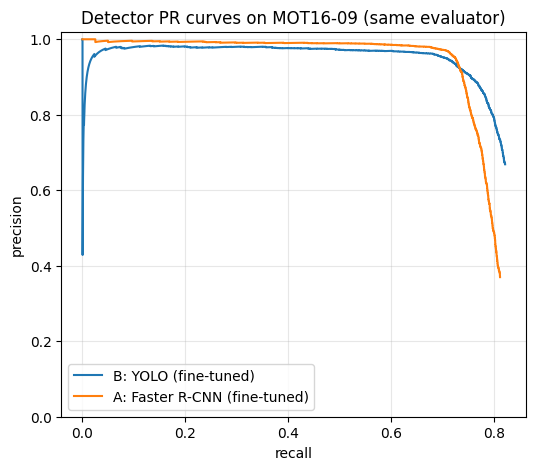

In [8]:
# 7. Detections of both detectors on all frames (cached on Drive), then the comparison
from ultralytics import YOLO
DETS = {}
cache_B = RESULTS/f'dets_B_yolo_{SEQ}.pkl'
if cache_B.exists(): DETS['B: YOLO (fine-tuned)'] = pickle.load(open(cache_B, 'rb'))
else:
    yolo = YOLO(str(BASE/'yolo_mot16_best.pt')); d = {}
    for r in yolo.predict(source=str(IMG_DIR), stream=True, conf=0.05, imgsz=IMGSZ, verbose=False):
        d[int(Path(r.path).stem)] = np.c_[r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy()]
    pickle.dump(d, open(cache_B, 'wb')); DETS['B: YOLO (fine-tuned)'] = d

cache_A = RESULTS/f'dets_A_frcnn_{SEQ}.pkl'
if cache_A.exists(): DETS['A: Faster R-CNN (fine-tuned)'] = pickle.load(open(cache_A, 'rb'))
elif A_DET_CKPT:
    frcnn = A_det.load_pedestrian_detector(str(A_DET_CKPT), dev)
    d, fps = A_det.detect_sequence(frcnn, str(SEQ_DIR), dev, score_thresh=0.05, verbose=False)
    print('Faster R-CNN speed on this GPU: %.1f fps' % fps); pickle.dump(d, open(cache_A, 'wb')); DETS['A: Faster R-CNN (fine-tuned)'] = d
elif A_DETS_CACHE:
    c = pickle.load(open(A_DETS_CACHE, 'rb')); DETS['A: Faster R-CNN (fine-tuned)'] = c['dets']
    print('Using the cached detections of Pipeline A (score >= 0.3 only, so low-score boxes are missing)')
else:
    print('No detections of Pipeline A available: only the YOLO detector is evaluated here.')

rows, curves, EV = [], {}, {}
for name, d in DETS.items():
    score, tp, gidx = eval_dets(d); EV[name] = (score, tp, gidx); s, curves[name] = summarize(score, tp, gidx); rows.append({'detector': name, **s})
det_table = pd.DataFrame(rows).set_index('detector'); display(det_table)
det_table.to_csv(RESULTS/'unified_part2_detectors.csv')

# sanity check against the evaluator of Pipeline A (it should give almost the same AP for its own detections)
if 'A: Faster R-CNN (fine-tuned)' in DETS:
    gt_A = A_data.parse_gt(str(SEQ_DIR)); chk = A_det.evaluate_detections(DETS['A: Faster R-CNN (fine-tuned)'], gt_A, IGN)
    print('Pipeline A evaluator on its detections: AP %.4f | this notebook: AP %.4f' % (chk['AP'], det_table.loc['A: Faster R-CNN (fine-tuned)', 'AP@0.5']))

plt.figure(figsize=(6, 5))
for name, (rec, prec) in curves.items(): plt.plot(rec, prec, label=name)
plt.xlabel('recall'); plt.ylabel('precision'); plt.ylim(0, 1.02); plt.grid(alpha=.3); plt.legend(); plt.title(f'Detector PR curves on {SEQ} (same evaluator)')
plt.savefig(RESULTS/'unified_part2_pr.png', dpi=130); plt.show()

In [ ]:
# 8. Which pedestrians does each detector find? Recall by visibility, at the same precision (0.80)
vis_bins = pd.cut(GT.vis, [-0.01, 0.25, 0.5, 0.75, 1.0], labels=['0-0.25', '0.25-0.5', '0.5-0.75', '0.75-1'])
res = {}
for name, (score, tp, gidx) in EV.items():
    th = op_score(score, tp, 0.8); m = (score >= th) & (tp == 1); found = np.zeros(len(GT), bool); found[gidx[m]] = True
    res[f'{name} (score>={th:.2f})'] = pd.Series(found).groupby(vis_bins, observed=True).mean().round(3)
vis_table = pd.DataFrame(res); vis_table.loc['all'] = [round(float(((EV[n][0] >= op_score(EV[n][0], EV[n][1], 0.8)) & (EV[n][1] == 1)).sum() / len(GT)), 3) for n in EV]
display(vis_table); print('GT boxes per visibility bin:', GT.groupby(vis_bins, observed=True).size().to_dict())
vis_table.to_csv(RESULTS/'unified_part2_recall_by_visibility.csv')

### How to read Part 2
- **AP and the PR curves** use the same evaluator for both detectors, so they can be compared directly (the scores of the two detectors are *not* on the same scale, so compare the curves, not the thresholds).
- **Recall by visibility at equal precision** shows which detector finds more of the partly hidden people. In Notebook 04 we found that most missed pedestrians of YOLO have visibility below 0.25.
- If the AP of Pipeline A is close to the value in its README (0.780), the evaluator agrees with their code. Pipeline A appears to evaluate every third frame of the sequence (its notebook prints 175 frames), so a small difference is expected.

### Part 2b: Coverage of the saved tracks (needs no weights of Pipeline A)

If the detector files of Pipeline A are not available, the same evaluator can still compare what each pipeline **finally outputs**. Every box of a track file is treated as a prediction, and we count how many ground-truth pedestrians are covered and how many boxes are false. Interpolated boxes of Pipeline A (gap filling) are included, because they are part of its output.

Note: `B_repaired` has the same boxes as `B_E2_finetuned_botsort` (the repair changes only the IDs), so small differences between these two rows come from the order in which equal-score boxes are matched.

In [ ]:
# 8b. Coverage of the saved tracks, by the same matching rule (no detector weights needed)
vis_bins = pd.cut(GT.vis, [-0.01, 0.25, 0.5, 0.75, 1.0], labels=['0-0.25', '0.25-0.5', '0.5-0.75', '0.75-1'])
cov_rows, cov_vis = {}, {}
for n in part1.index:
    t = pd.read_csv(TE_TRACKERS/n/'data'/f'{SEQ}.txt', header=None)
    d = {int(f): np.c_[g[2].values, g[3].values, g[2].values + g[4].values, g[3].values + g[5].values, np.ones(len(g))] for f, g in t.groupby(0)}
    score, tp, gidx = eval_dets(d); found = np.zeros(len(GT), bool); found[gidx[tp == 1]] = True
    cov_rows[n] = dict(boxes=len(t), recall=round(float(tp.sum() / len(GT)), 3), missed=int(len(GT) - tp.sum()),
                       false_boxes=int((1 - tp).sum()), precision=round(float(tp.mean()), 3))
    cov_vis[n] = pd.Series(found).groupby(vis_bins, observed=True).mean().round(3)
cov_table = pd.DataFrame(cov_rows).T; display(cov_table); display(pd.DataFrame(cov_vis))
cov_table.to_csv(RESULTS/'unified_part2b_track_coverage.csv'); pd.DataFrame(cov_vis).to_csv(RESULTS/'unified_part2b_coverage_by_visibility.csv')

## Part 3: Swap the detector inside the tracker of Pipeline A

The tracker of Pipeline A takes detections and ReID embeddings per frame. We give it:
- its own Faster R-CNN detections (a check that we reproduce its published result), and
- the YOLO detections, embedded with its own ReID model.

The detector is the only change, so the difference shows the effect of the detector in the same tracker. The score scale of YOLO differs from Faster R-CNN, so we also test lower tracker thresholds.

In [9]:
# 9. Run the tracker of Pipeline A with both detectors (needs the ReID weights of Pipeline A)
SWAP_OK = A_REID_CKPT is not None and 'A: Faster R-CNN (fine-tuned)' in DETS
if not SWAP_OK:
    print('Skipped: the ReID weights or the detections of Pipeline A are missing.')
else:
    reid_A = A_reid.load_reid(str(A_REID_CKPT), dev)
    final = json.load(open('/content/pipelineA/results/tables/final_run.json'))['tracker_config']
    base_cfg = {k: v for k, v in final.items() if k in A_tracker.TrackerConfig.__dataclass_fields__}      # final settings of Pipeline A
    FLOOR = 0.3                                                                                          # boxes below this are never used (as in Pipeline A)

    def embed_all(dets):
        feats, kept = {}, {}
        for f in sorted(dets):
            d = np.asarray(dets[f], float).reshape(-1, 5); d = d[d[:, 4] >= FLOOR]; kept[f] = d
            img = cv2.imread(str(IMG_DIR/f'{f:06d}.jpg')); feats[f] = A_reid.embed_crops(reid_A, img, d[:, :4], dev)
        return kept, feats

    def run_A_tracker(name, dets, feats, **override):
        cfg = A_tracker.TrackerConfig(**{**base_cfg, **override})
        res = A_tracker.run_tracker(dets, feats, cfg, image_size=(W_IMG, H_IMG))
        d = TE_TRACKERS/name/'data'; d.mkdir(parents=True, exist_ok=True); A_tracker.save_mot(res, str(d/f'{SEQ}.txt'))

    detsA, featsA = embed_all(DETS['A: Faster R-CNN (fine-tuned)'])
    run_A_tracker('S_Adet_Atrk_reproduction', detsA, featsA)
    detsB, featsB = embed_all(DETS['B: YOLO (fine-tuned)'])
    for hi, lo in [(0.7, 0.6), (0.6, 0.5), (0.5, 0.4), (0.4, 0.3)]:
        run_A_tracker(f'S_Bdet_Atrk_hi{hi}_lo{lo}', detsB, featsB, high_thresh=hi, low_thresh=lo)
    names = run_trackeval(); part3 = collect_results(names)
    keep = [n for n in part3.index if n.startswith(('A_', 'B_', 'S_'))]
    display(part3.loc[keep].round(2)); part3.loc[keep].round(3).to_csv(RESULTS/'unified_part3_detector_swap.csv')

,HOTA,DetA,AssA,MOTA,IDF1,IDSW,Frag,CLR_FP,CLR_FN,pred_ids
run,,,,,,,,,,
A_published,50.40,53.97,47.11,55.83,60.35,35.0,51.0,1073.0,1214.0,54
B_E0_pretrained_bytetrack,48.11,54.50,42.71,59.29,57.37,46.0,69.0,735.0,1359.0,92
B_E1_finetuned_bytetrack,47.94,58.99,39.12,64.77,55.77,42.0,91.0,532.0,1278.0,73
B_E2_finetuned_botsort,48.40,60.36,38.95,68.54,55.65,46.0,95.0,462.0,1146.0,72
B_repaired,55.30,60.25,50.89,68.35,68.04,56.0,96.0,462.0,1146.0,72
S_Adet_Atrk_reproduction,50.21,53.94,46.79,55.85,62.38,33.0,51.0,1073.0,1215.0,54
S_Bdet_Atrk_hi0.4_lo0.3,47.91,59.96,38.40,69.15,55.93,50.0,65.0,364.0,1208.0,49
S_Bdet_Atrk_hi0.5_lo0.4,47.73,59.56,38.37,68.61,54.70,40.0,61.0,290.0,1320.0,41
S_Bdet_Atrk_hi0.6_lo0.5,51.08,58.18,44.93,67.38,62.65,30.0,61.0,229.0,1456.0,39


### How to read Part 3
- `S_Adet_Atrk_reproduction` should be close to `A_published` (HOTA about 50, IDF1 about 60 to 62). If it is, the setup of Pipeline A is reproduced correctly in this environment.
- The rows `S_Bdet_Atrk_*` are the YOLO detections in the tracker of Pipeline A. Compare them with `S_Adet_Atrk_reproduction` to see the effect of the detector, and with `B_E2_finetuned_botsort` to see the effect of the tracker.
- A detector with fewer false positives lowers CLR_FP and raises MOTA. A detector that finds more people lowers CLR_FN.
- The four threshold pairs were compared on this same sequence, so the best YOLO row is optimistic. Report the whole sweep.

## Part 4: Both ReID models on one protocol

All models are tested on the same query/gallery split of MOT16-09 crops: queries are the early crops of each person, the gallery is the late crops of all people, and the middle 20% is dropped (protocol of Notebook 05). Each model receives crops in its own input size.

In [ ]:
# 10. ReID comparison (needs the ReID weights of Pipeline B and its crop dataset from Notebook 05, and the ReID weights of Pipeline A)
ZIP, B_REID_CKPT = BASE/'reid_crops.zip', BASE/'reid_best.pt'
if not (A_REID_CKPT and ZIP.exists() and B_REID_CKPT.exists()):
    print('Skipped: need the ReID weights of Pipeline A, reid_crops.zip and reid_best.pt (from Notebook 05).')
else:
    if not Path('/content/reid_crops').exists(): shutil.unpack_archive(str(ZIP), '/content')
    index = pd.read_csv('/content/reid_crops/index.csv'); val_df = index[index.seq == SEQ].reset_index(drop=True)
    q_rows, g_rows = [], []
    for pid, g in val_df.groupby('pid'):
        g = g.sort_values('frame')
        if len(g) < 6: continue
        n = len(g); q_rows.append(g.iloc[: int(n * 0.4)]); g_rows.append(g.iloc[int(n * 0.6):])
    q_df, g_df = pd.concat(q_rows).reset_index(drop=True), pd.concat(g_rows).reset_index(drop=True); qp, gp = q_df.pid.values, g_df.pid.values
    print('queries:', len(q_df), '| gallery:', len(g_df), '| identities:', q_df.pid.nunique())

    MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
    def make_tf(h, w): return T.Compose([T.Resize((h, w)), T.ToTensor(), T.Normalize(MEAN, STD)])

    class ReIDNet(nn.Module):                      # Pipeline B ReID model (same as Notebook 05)
        def __init__(self, n_classes=0, pretrained=False):
            super().__init__()
            r = torchvision.models.resnet50(weights='IMAGENET1K_V2' if pretrained else None)
            r.layer4[0].conv2.stride = (1, 1); r.layer4[0].downsample[0].stride = (1, 1)
            self.backbone = nn.Sequential(r.conv1, r.bn1, r.relu, r.maxpool, r.layer1, r.layer2, r.layer3, r.layer4)
            self.pool = nn.AdaptiveAvgPool2d(1); self.bn = nn.BatchNorm1d(2048); self.bn.bias.requires_grad_(False)
        def forward(self, x):
            f = self.pool(self.backbone(x)).flatten(1); return f, self.bn(f), None

    @torch.no_grad()
    def embed_paths(fn, paths, tf, bs=128):
        out = []
        for i in range(0, len(paths), bs):
            x = torch.stack([tf(Image.open(p).convert('RGB')) for p in paths[i:i + bs]]).to(dev)
            with torch.autocast(dev.type, dtype=torch.float16, enabled=(dev.type == 'cuda')): out.append(F.normalize(fn(x).float(), dim=1).cpu())
        return torch.cat(out).numpy()

    def eval_reid(qf, gf, qp, gp):
        sim = qf @ gf.T; aps, cmc, nv = [], np.zeros(gf.shape[0]), 0
        for i in range(len(qf)):
            m = (gp[np.argsort(-sim[i])] == qp[i]).astype(int)
            if m.sum() == 0: continue
            nv += 1; cmc[np.argmax(m):] += 1; aps.append((np.cumsum(m) / (np.arange(len(m)) + 1) * m).sum() / m.sum())
        c = cmc / nv; return dict(mAP=round(float(np.mean(aps)), 4), R1=round(float(c[0]), 4), R5=round(float(c[4]), 4), R10=round(float(c[9]), 4))

    sdB = {k: v for k, v in torch.load(B_REID_CKPT, map_location=dev).items() if not k.startswith('cls.')}
    modelB = ReIDNet().to(dev); modelB.load_state_dict(sdB); modelB.eval()
    modelB0 = ReIDNet(pretrained=True).to(dev).eval()
    modelA = A_reid.load_reid(str(A_REID_CKPT), dev); modelA0 = A_reid.ImageNetBaseline().to(dev).eval()
    models = {'B: ResNet-50 ImageNet only': (lambda x: modelB0(x)[0], make_tf(256, 128)),
              'B: ResNet-50 + BNNeck, ID + triplet': (lambda x: modelB(x)[1], make_tf(256, 128)),
              'A: ResNet-18 ImageNet only': (modelA0.forward_once, make_tf(128, 64)),
              'A: Siamese ResNet-18, triplet': (modelA.forward_once, make_tf(128, 64))}
    rows = {}
    for name, (fn, tf) in models.items(): rows[name] = eval_reid(embed_paths(fn, q_df.path.tolist(), tf), embed_paths(fn, g_df.path.tolist(), tf), qp, gp)
    reid_table = pd.DataFrame(rows).T; display(reid_table); reid_table.to_csv(RESULTS/'unified_part4_reid.csv')

### How to read Part 4
- All four rows use the same crops and the same split, so the values can be compared. The ImageNet rows show how much each trained model adds.
- Pipeline B uses a larger network and a larger input. Part of any difference may come from this size, not only from the training method.
- The numbers published in the two pipelines (Rank-1 0.914 for A and 0.922 for B) were measured with different protocols and should not be quoted as a comparison.
- The ReID model of Pipeline B was selected by its score on this same validation sequence, and the test crops come from the same crop extraction as its training crops. Both effects favor Pipeline B.

In [ ]:
# 11. One summary table for the report and the slides
src_table = part3 if 'part3' in globals() else part1
labels = {'A_published': 'Pipeline A (published tracks)',
          'S_Adet_Atrk_reproduction': 'Pipeline A (reproduced in this notebook)',
          'B_E2_finetuned_botsort': 'Pipeline B (BoT-SORT)',
          'B_repaired': 'Pipeline B (+ ReID repair)',
          'S_Bdet_Atrk_hi0.6_lo0.5': 'Hybrid: Pipeline B detector + Pipeline A tracker (thresholds 0.6/0.5)'}
rows = [n for n in labels if n in src_table.index]
summary = src_table.loc[rows, ['HOTA', 'DetA', 'AssA', 'MOTA', 'IDF1', 'IDSW', 'CLR_FP', 'CLR_FN', 'pred_ids']].copy()
summary.index = [labels[n] for n in rows]
display(summary.round(2)); summary.round(3).to_csv(RESULTS/'unified_summary.csv')
print('The hybrid thresholds were picked from a 4-value sweep on this same sequence, so that row is optimistic.')
print('Files saved in', RESULTS)

## Part 5: Per-person analysis (how many people keep one ID?)

For each ground-truth person, the tracks are matched frame by frame (IoU 0.5, one-to-one). We count how many different predicted IDs follow the person and what share of the person's frames is covered. The same rule is used for every run, so the pipelines can be compared. The numbers can differ slightly from the file `per_person.csv` of Pipeline A, which uses its own matching code.

In [10]:
# 12. Per-person analysis for every run (same matching rule)
from scipy.optimize import linear_sum_assignment
GT_ID = pd.DataFrame({'frame': ped[:, 0].astype(int), 'gt_id': ped[:, 1].astype(int), 'x1': ped[:, 2], 'y1': ped[:, 3], 'x2': ped[:, 2] + ped[:, 4], 'y2': ped[:, 3] + ped[:, 5]})
G_FRAMES = {f: g for f, g in GT_ID.groupby('frame')}

def per_person(run):
    t = pd.read_csv(TE_TRACKERS/run/'data'/f'{SEQ}.txt', header=None)
    P = {int(f): g for f, g in t.groupby(0)}
    matched = {}                                              # gt_id -> predicted id in every matched frame
    for f, g in G_FRAMES.items():
        p = P.get(f)
        if p is None: continue
        pb = np.c_[p[2].values, p[3].values, p[2].values + p[4].values, p[3].values + p[5].values]
        iou = iou_xyxy(g[['x1', 'y1', 'x2', 'y2']].values, pb); r, c = linear_sum_assignment(-iou)
        for i, j in zip(r, c):
            if iou[i, j] >= 0.5: matched.setdefault(int(g.gt_id.iloc[i]), []).append(int(p[1].iloc[j]))
    rows = []
    for gid, g in GT_ID.groupby('gt_id'):
        ids = matched.get(int(gid), [])
        rows.append(dict(gt_id=int(gid), frames=len(g), coverage=len(ids) / len(g), num_ids=len(set(ids))))
    return pd.DataFrame(rows)

runs = [n for n in ['A_published', 'B_E2_finetuned_botsort', 'B_repaired', 'S_Bdet_Atrk_hi0.6_lo0.5'] if (TE_TRACKERS/n/'data').exists()]
summ = {}
for n in runs:
    pp = per_person(n); ll = pp[pp.frames >= 100]; pp.round(3).to_csv(RESULTS/f'per_person_{n}.csv', index=False)
    summ[n] = dict(people=len(pp), long_lived_100f=len(ll), long_lived_single_id=int((ll.num_ids == 1).sum()),
                   long_lived_perfect=int(((ll.num_ids == 1) & (ll.coverage >= 0.9)).sum()),
                   mean_coverage=round(float(ll.coverage.mean()), 3), mean_ids_per_person=round(float(ll.num_ids.mean()), 2))
per_table = pd.DataFrame(summ).T; display(per_table); per_table.to_csv(RESULTS/'unified_part5_per_person.csv')
print('perfect = one predicted ID and at least 90% of the frames covered; long-lived = at least 100 frames')

,people,long_lived_100f,long_lived_single_id,long_lived_perfect,mean_coverage,mean_ids_per_person
A_published,25.0,18.0,5.0,2.0,0.767,2.94
B_E2_finetuned_botsort,25.0,18.0,3.0,1.0,0.775,3.50
B_repaired,25.0,18.0,3.0,1.0,0.775,3.78
S_Bdet_Atrk_hi0.6_lo0.5,25.0,18.0,4.0,2.0,0.720,2.78


perfect = one predicted ID and at least 90% of the frames covered; long-lived = at least 100 frames


## Part 6: Speed of both detectors on the same GPU

Both detectors process the same 100 frames in the same session, so the hardware is the same. Times are per frame, including the model and the post-processing of its library, after 5 warm-up frames. The whole-pipeline speeds of each pipeline (with ReID and tracking) are in the speed tables of the notebooks that produced them.

In [11]:
# 13. Speed on one GPU: detectors on the same 100 frames
N_T = 100
frames_t = [cv2.imread(str(IMG_DIR/f'{f:06d}.jpg')) for f in range(1, N_T + 1)]
def timed(fn, warm=5):
    for im in frames_t[:warm]: fn(im)
    if dev.type == 'cuda': torch.cuda.synchronize()
    t0 = time.time()
    for im in frames_t: fn(im)
    if dev.type == 'cuda': torch.cuda.synchronize()
    return (time.time() - t0) / len(frames_t) * 1000

speed_rows = {}
if A_DET_CKPT:
    frcnn_t = A_det.load_pedestrian_detector(str(A_DET_CKPT), dev)
    speed_rows['A: Faster R-CNN, detector only'] = timed(lambda im: A_det.detect(frcnn_t, im, dev, score_thresh=0.3))
yolo_t = YOLO(str(BASE/'yolo_mot16_best.pt'))
speed_rows['B: YOLO, detector only'] = timed(lambda im: yolo_t.predict(im, conf=0.1, imgsz=IMGSZ, verbose=False))
yolo_k = YOLO(str(BASE/'yolo_mot16_best.pt'))
speed_rows['B: YOLO + BoT-SORT (detection and tracking)'] = timed(lambda im: yolo_k.track(im, persist=True, tracker='botsort.yaml', conf=0.1, imgsz=IMGSZ, verbose=False))
speed_t = pd.DataFrame({'ms_per_frame': speed_rows}).round(1); speed_t['fps'] = (1000 / speed_t['ms_per_frame']).round(1); speed_t['gpu'] = GPU
display(speed_t); speed_t.to_csv(RESULTS/'unified_part6_speed.csv')

requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 2 packages in 427ms
Prepared 1 package in 438ms
Installed 1 package in 2ms
 + lap==0.5.13

requirements: AutoUpdate success ✅ 1.2s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect



,ms_per_frame,fps,gpu
"A: Faster R-CNN, detector only",43.0,23.3,NVIDIA A100-SXM4-40GB
"B: YOLO, detector only",15.1,66.2,NVIDIA A100-SXM4-40GB
B: YOLO + BoT-SORT (detection and tracking),33.1,30.2,NVIDIA A100-SXM4-40GB


## Checklist before moving on
- [ ] Part 1 table: HOTA, IDF1, MOTA, IDSW, CLR_FP, CLR_FN for A and B from the same code
- [ ] Part 2: AP and PR curves for both detectors; the sanity check against the evaluator of Pipeline A is close
- [ ] Part 3: the reproduction row is close to the published result of Pipeline A; the detector swap rows are compared with it
- [ ] Part 4: ReID table on one protocol
- [ ] Summary table (cell 11) includes the hybrid row if Part 3 was run
- [ ] Summary table (cell 11) includes the hybrid row if Part 3 was run
- [ ] Save the figures: `unified_part1_bars.png`, `unified_part2_pr.png`, and the CSV files, for the report and the slides

## Limitations
- One validation sequence (MOT16-09). Thresholds and models of both pipelines were selected on this sequence, so all scores are optimistic.
- The YOLO scores and the Faster R-CNN scores have different scales. The comparison at equal precision and the threshold sweep reduce this problem, but do not remove it.
- Speed is measured on the hardware of each run and is only comparable when both detectors run on the same GPU.
- Pipeline A's tracker and ReID model were tuned for its own detector. Results with the YOLO detector may improve with further tuning.
- The hybrid row (Pipeline B detector in the tracker of Pipeline A) uses thresholds chosen on this sequence, so it is optimistic.
- The hybrid row (Pipeline B detector in the tracker of Pipeline A) uses thresholds chosen on this sequence, so it is optimistic.